# Explore the Yelp data (McDonald's and IKEA)

Before a model reads any review, we look at the data: which locations are reviewed, how the ratings are distributed, and who writes reviews.

In this notebook, we will:
1. Load the McDonald's and IKEA locations and compare their ratings.
2. Load all IKEA reviews and explore stars, time, stores and review length.
3. Read some reviews and search for a topic.
4. Prepare a small, anonymized sample of 500 reviews for notebooks 03–05.

**Time:** about 15 minutes. This notebook needs no API key and costs nothing.

**Before you start: get the data from Moodle**
1. Download `llm_fundamentals_data.zip` from Moodle (Week 10).
2. Drag the zip file into the file Explorer, onto the folder `data`.
3. Run the cells below: the cell **Unzip the data** unpacks the zip into `data`.

**Self-check:** allow about 5 additional minutes for the questions at the end of the core exercise. Optional extensions take extra time.

## Libraries and settings

In [1]:
# Libraries
import os
import platform
import zipfile
from datetime import datetime
from platform import python_version

import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# Course helpers: DATA is the folder 'data', anonymize() removes personal details
from llm_course import DATA, anonymize

# Show current working directory
print(os.getcwd())

/workspaces/llm_fundamentals/01_Explore_Yelp_Data


## Unzip the data

Unpacks `data/llm_fundamentals_data.zip` from Moodle into `data`. Only needed once.

In [2]:
# Zip file from Moodle, dragged onto the folder data
ZIP_FILE = DATA / 'llm_fundamentals_data.zip'

if os.path.exists(DATA / 'ikea_reviews.csv'):
    print('Data already unzipped.')
elif os.path.exists(ZIP_FILE):
    with zipfile.ZipFile(ZIP_FILE) as z:
        z.extractall(DATA)
        print('Unzipped into data:', z.namelist())
else:
    print('Zip file not found: download llm_fundamentals_data.zip from Moodle (Week 10),\n'
          'drag it onto the folder data, then run this cell again.')

Data already unzipped.


## Part 1: The locations

### Import the business records

In [3]:
# Read the McDonald's and IKEA locations
df_bus = pd.read_csv(DATA / 'businesses_mcdonalds_ikea.csv')

# Shape and first rows
print(df_bus.shape)
df_bus.head(5)

(716, 7)


,chain,business_id,name,city,state,stars,review_count
0,McDonald's,yM8LlTInbQH4FwWC97lz6w,McDonald's,St. Louis,MO,1.5,100
1,McDonald's,aNXw3PkXVt8ANwLyCfcmpg,McDonald's,Lansdale,PA,1.5,17
2,McDonald's,gb7JjRJtzWDsIWpJihZhBQ,McDonald's,Pennsville,NJ,2.0,20
3,McDonald's,9qxMhGWjGsuPUoQB3Y74Wg,McDonald's,St. Louis,MO,1.5,62
4,McDonald's,A1lAqN3SOaBLoo6NqVcy4Q,McDonald's,Brandon,FL,2.0,6


### Number of locations and reviews per chain

In [4]:
# Locations, reviews and mean rating per chain
summary = df_bus.groupby('chain').agg(
    locations=('business_id', 'count'),
    reviews=('review_count', 'sum'),
    mean_stars=('stars', 'mean'),
)
summary.round(2)

,locations,reviews,mean_stars
chain,,,
IKEA,8,1688,3.38
McDonald's,708,17415,1.87


### Average rating: per location vs. per review

`mean_stars` counts every location once. A location with 500 reviews should count more than one with 5 reviews, so we weight each location by its number of reviews.

In [5]:
# Weighted average: sum of (stars x reviews) divided by the sum of reviews
df_bus['stars_x_reviews'] = df_bus['stars'] * df_bus['review_count']
totals = df_bus.groupby('chain')[['stars_x_reviews', 'review_count']].sum()
summary['weighted_stars'] = totals['stars_x_reviews'] / totals['review_count']

summary.round(2)

,locations,reviews,mean_stars,weighted_stars
chain,,,,
IKEA,8,1688,3.38,3.31
McDonald's,708,17415,1.87,1.78


### Distribution of the location ratings

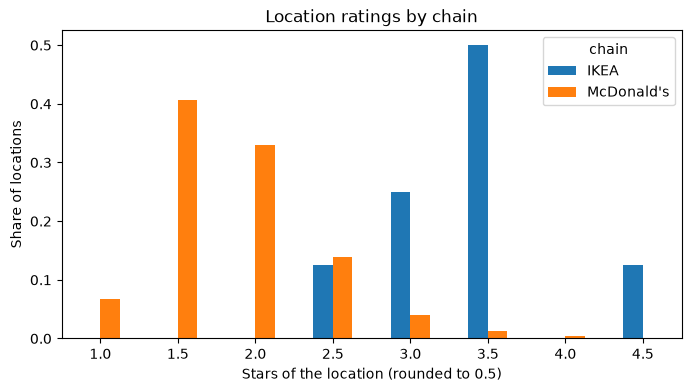

In [6]:
# Share of locations per star rating, for each chain
shares = pd.crosstab(df_bus['stars'], df_bus['chain'], normalize='columns')

shares.plot.bar(figsize=(8, 4))
plt.title('Location ratings by chain')
plt.xlabel('Stars of the location (rounded to 0.5)')
plt.ylabel('Share of locations')
plt.xticks(rotation=0)
plt.show()

### The IKEA locations

In [7]:
# All IKEA records: 6 stores and 2 store restaurants
df_bus.loc[df_bus['chain'] == 'IKEA', ['name', 'city', 'state', 'stars', 'review_count']]

,name,city,state,stars,review_count
708,IKEA,St. Louis,MO,2.5,13
709,IKEA Restaurant,St. Louis,MO,3.5,218
710,IKEA,Philadelphia,PA,3.0,365
711,IKEA,Conshohocken,PA,3.0,277
712,IKEA,Edmonton,AB,3.5,102
713,IKEA,Fishers,IN,3.5,309
714,IKEA,Tampa,FL,3.5,389
715,IKEA Restaurant,Tampa,FL,4.5,15


## Part 2: The IKEA reviews

### Import the IKEA reviews

In [8]:
# Read all IKEA reviews
df = pd.read_csv(DATA / 'ikea_reviews.csv', parse_dates=['date'])

# Shape and first rows
print(df.shape)
df.head(5)

(1743, 8)


,review_id,business_id,store,city,state,stars,date,text
0,8iqJQ4zy4nttfnf-sKy1sw,f5VqTIMC-9Iw747SwhS0rg,IKEA Restaurant,St. Louis,MO,5,2016-02-23 21:15:35,"This place is very awesome! Cheap furniture, l..."
1,A28tDsxpZu3Z9615P29yww,f5VqTIMC-9Iw747SwhS0rg,IKEA Restaurant,St. Louis,MO,3,2017-01-14 21:06:13,Cool store for college and city living. Not im...
2,KdgazqlrUjMsXBa08hXAug,f5VqTIMC-9Iw747SwhS0rg,IKEA Restaurant,St. Louis,MO,4,2017-03-15 18:53:43,I love this place!! I was worried about it bei...
3,B09-KRznnFn-Nf7MurCsOg,f5VqTIMC-9Iw747SwhS0rg,IKEA Restaurant,St. Louis,MO,4,2015-12-05 03:25:39,First timer!\nWe ate first and I thought it wa...
4,c68rTxDCEs_4-pNC5_2Pig,f5VqTIMC-9Iw747SwhS0rg,IKEA Restaurant,St. Louis,MO,2,2016-12-19 07:19:40,This store is definitely NOT user-friendly for...


### Star distribution of the reviews

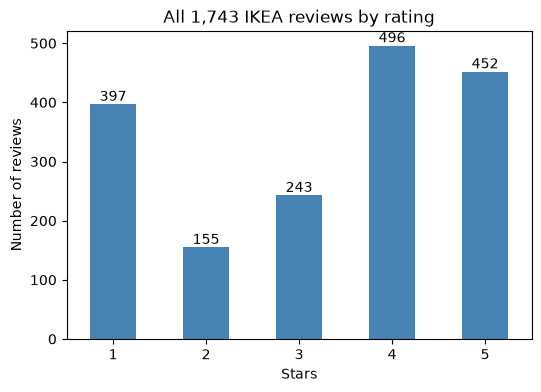

In [9]:
# Number of reviews per star rating
counts = df['stars'].value_counts().sort_index()

ax = counts.plot.bar(color='steelblue', figsize=(6, 4))
ax.bar_label(ax.containers[0])
plt.title(f'All {len(df):,} IKEA reviews by rating')
plt.xlabel('Stars')
plt.ylabel('Number of reviews')
plt.xticks(rotation=0)
plt.show()

Read the star-distribution plot: are reviews concentrated at the extremes or in the middle? Describe what you actually see.

A **J-shape** (many high ratings, another peak at low ratings, fewer in between) is common in online reviews. People choose whether to write a review. Even a perfect summary describes those reviewers, not all customers.

### Reviews over time

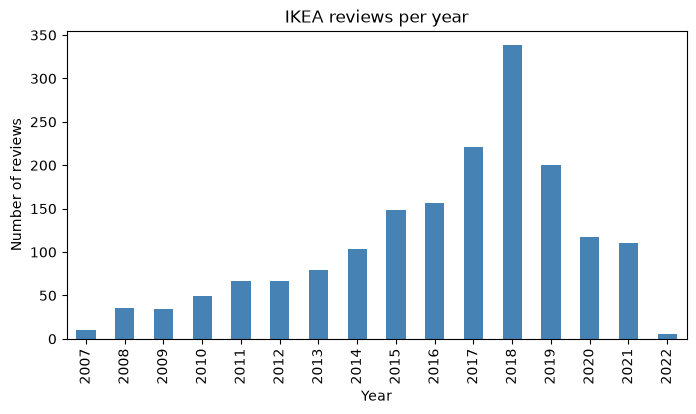

In [10]:
# Number of reviews per year
df['year'] = df['date'].dt.year
per_year = df['year'].value_counts().sort_index()

per_year.plot.bar(color='steelblue', figsize=(8, 4))
plt.title('IKEA reviews per year')
plt.xlabel('Year')
plt.ylabel('Number of reviews')
plt.show()

### Ratings by store

In [11]:
# Number of reviews and mean rating per store
by_store = df.groupby(['store', 'city']).agg(
    reviews=('review_id', 'count'),
    mean_stars=('stars', 'mean'),
)
by_store.sort_values('reviews', ascending=False).round(2)

reviews  mean_stars
store           city                             
IKEA            Tampa             404        3.32
                Philadelphia      371        2.88
                Fishers           318        3.72
                Conshohocken      285        2.97
IKEA Restaurant St. Louis         226        3.39
IKEA            Edmonton          109        3.39
IKEA Restaurant Tampa              17        4.29
IKEA            St. Louis          13        2.54

### Review length

count    1743.0
mean      141.4
std       123.9
min         7.0
25%        59.0
50%       105.0
75%       183.0
max       922.0
Name: words, dtype: float64


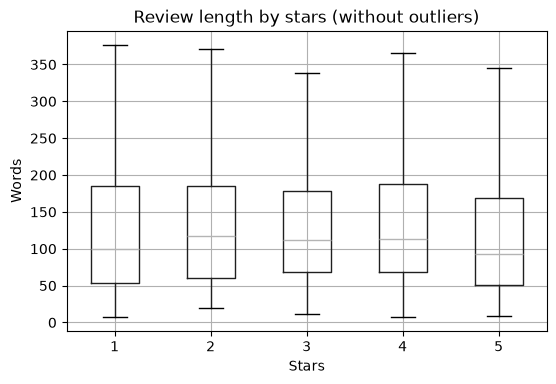

In [12]:
# Number of words per review
df['words'] = df['text'].str.split().str.len()
print(df['words'].describe().round(1))

# Review length by star rating
df.boxplot(column='words', by='stars', showfliers=False, figsize=(6, 4))
plt.suptitle('')
plt.title('Review length by stars (without outliers)')
plt.xlabel('Stars')
plt.ylabel('Words')
plt.show()

## Part 3: Read reviews

Numbers hide what people actually write. Read at least one review per star rating.

In [13]:
# One random review for each star rating
for stars in [1, 2, 3, 4, 5]:
    review = df[df['stars'] == stars].sample(1, random_state=42).iloc[0]
    print(stars, 'stars |', review['store'], '|', review['city'])
    print(review['text'][:500], '\n')

1 stars | IKEA | Philadelphia
I bought $4349 of kitchen cabinets from Ikea.  As I assembled the cabinets there was one entire panel missing from one base csbinet, and some dowels and screws missing from several base cabinets.  I went to Plymouth Meeting and they were able to quickly help me.  Then I moved on to wall cabinets and now a small panel from corner angle was missing.  I got my roommate to send me a pic of my receipt and this time went to S Philly Ikea straight from work.  I showed it to the customer service lady Cl 

2 stars | IKEA | Conshohocken
The COUCH Saga!

4 months after we bought our awesome Karlstad couch, the arm pulled off of it. So with a heavy heart, we went back to IKEA and showed them a few pictures (it was huge, we'd had it delivered) and after some computer issues we were told they'd be sending us a new one two days later, a Friday, between 1 and five. 

Now don't get me wrong, our entire apartment is IKEA and we adore it. They'll probably be getting money fo

### Search for a topic

In [14]:
# TODO: try other topics, e.g. 'assembly', 'return', 'parking', 'staff'
topic = 'meatball'

hits = df[df['text'].str.contains(topic, case=False)]
print(f"{len(hits)} reviews mention '{topic}'")
print(f"Mean stars: {hits['stars'].mean():.2f} (all reviews: {df['stars'].mean():.2f})")
hits[['stars', 'store', 'text']].head(5)

305 reviews mention 'meatball'
Mean stars: 3.91 (all reviews: 3.26)


,stars,store,text
1,3,IKEA Restaurant,Cool store for college and city living. Not im...
3,4,IKEA Restaurant,First timer!\nWe ate first and I thought it wa...
4,2,IKEA Restaurant,This store is definitely NOT user-friendly for...
7,4,IKEA Restaurant,Food is good and for a family of 6 it is the s...
16,5,IKEA Restaurant,LOVE!!! Check out the 'as-is' in the self-serv...


## Part 4: Prepare a sample for the API notebooks

Reviews can contain names, phone numbers and other personal details. **We never send personal data to an external API.** Notebooks 03–05 therefore use a prepared sample:

1. Draw a random sample of **500 reviews**. That is enough for all exercises and keeps the notebooks fast.
2. Remove personal details with `anonymize()`: names of people, e-mail addresses and phone numbers. It runs on this computer (libraries Presidio and spaCy), not through an API. Company names, places and dates stay, because the model needs them to understand a review.
3. Check the result and save it.

### How `anonymize()` works: one example

In [15]:
# A made-up text with a name, a phone number and an e-mail address
example = ('I asked for John Smith at the IKEA store in Tampa. '
           'Call me on 813-555-0199 or write to john.smith@example.com.')

print(example)
print(anonymize(example))

I asked for John Smith at the IKEA store in Tampa. Call me on 813-555-0199 or write to john.smith@example.com.
I asked for <REDACTED> at the IKEA store in Tampa. Call me on <REDACTED> or write to <REDACTED>.


### Draw the sample

Some review texts appear more than once in the data. We keep each text once. We also leave out the three example reviews that notebook 03 shows to the model: a review used as an example must not be used again to test the model.

In [16]:
# Reviews whose text appears more than once
duplicates = df[df.duplicated('text', keep=False)]
print('Rows with a text that appears more than once:', len(duplicates))

# Keep each text once and leave out the three example reviews of notebook 03
examples = pd.read_json(DATA / 'fewshot_examples.json')
unique = df.drop_duplicates('text')
unique = unique[~unique['text'].isin(examples['text'])]
print('All reviews:', len(df), '| unique reviews without the examples:', len(unique))

Rows with a text that appears more than once: 9
All reviews: 1743 | unique reviews without the examples: 1736


In [17]:
# Random sample of 500 reviews. The fixed random_state gives everybody the same sample.
sample = unique.sample(500, random_state=42)
sample = sample[['store', 'city', 'stars', 'date', 'text']].reset_index(drop=True)

# Short IDs R001 ... R500: easy to read and to cite later
sample.insert(0, 'id', [f'R{i:03d}' for i in range(1, 501)])

sample['stars'].value_counts().sort_index()

stars
1    112
2     51
3     70
4    141
5    126
Name: count, dtype: int64

### Anonymize the sample

In [18]:
# Keep the original text for the comparison below, then anonymize (about 20 seconds)
sample['original'] = sample['text']
sample['text'] = [anonymize(text) for text in tqdm(sample['original'])]

changed = sample[sample['text'] != sample['original']]
print('Reviews with at least one replacement:', len(changed), 'of', len(sample))

  0%|          | 0/500 [00:00<?, ?it/s]

Reviews with at least one replacement: 126 of 500


### Check the result

Automatic anonymization makes mistakes: it can miss a name, and it can remove harmless words. Compare some texts before and after.

In [19]:
# Before and after, for five changed reviews
pd.set_option('display.max_colwidth', 400)
changed[['id', 'original', 'text']].head(5)

,id,original,text
0,R001,Great deals on furniture and the food court has a lot to choose from at a pretty good price! Was a big fan of the Swedish Meatballs! The store has 2 floors: Top floor is a show room showing what is available and how it can be used in your home based on the mock display. Take note of the item number and location and then venture over to the 1st floor. Here you can find your chosen furniture pac...,Great deals on furniture and the food court has a lot to choose from at a pretty good price! Was a big fan of the Swedish Meatballs! The store has 2 floors: Top floor is a show room showing what is available and how it can be used in your home based on the mock display. Take note of the item number and location and then venture over to the 1st floor. Here you can find your chosen furniture pac...
2,R003,What a disaster!! Order online and wanted the furniture shipped to Sarasota. First they told me to expect delivery in less than a week. Then they sent me an email saying to expect delivery in 11 days. No word or update. Spent 40 minutes calling customer service only to be told that now delivery would be another 7 days. This time I got a confirmation but on day 6 no word from the delivery...,What a disaster!! <REDACTED> online and wanted the furniture shipped to Sarasota. First they told me to expect delivery in less than a week. Then they sent me an email saying to expect delivery in 11 days. No word or update. Spent 40 minutes calling customer service only to be told that now delivery would be another 7 days. This time I got a confirmation but on day 6 no word from the del...
3,R004,"Now I didn't actually go into the store proper but I did order something online and goto the store and pick it up. This process was seamless. Tons of parking, employees available to grab my item. Too easy, I hate shopping so if I goto a store I want in and out quick and they delivered:)","Now I didn't actually go into the store proper but I did order something online and goto the store and pick it up. This process was seamless. <REDACTED> of parking, employees available to grab my item. Too easy, I hate shopping so if I goto a store I want in and out quick and they delivered:)"
12,R013,"This IKEA was there for us when we first moved to Philly. So much cheap, yet durable furniture at low, low prices. How could we, as poor college students, resist? Putting together the furniture by myself gave me a sense of self-empowerment. And after a long hard day of looking at furniture and making decisions, what better way to reward yourself than with a heaping plate full of Swedish meatba...","This IKEA was there for us when we first moved to <REDACTED>. So much cheap, yet durable furniture at low, low prices. How could we, as poor college students, resist? Putting together the furniture by myself gave me a sense of self-empowerment. And after a long hard day of looking at furniture and making decisions, what better way to reward yourself than with a heaping plate full of Swedish me..."
14,R015,IKEA is a great place to find a great deal and quite an experience just to walk through. Also - before I became vegetarian I LOVED the meatballs and gravy...now I love the Veggie balls...very flavorful for a quick little lunch or dinner while shopping.,IKEA is a great place to find a great deal and quite an experience just to walk through. Also - before I became vegetarian I LOVED the meatballs and gravy...now I love the <REDACTED> balls...very flavorful for a quick little lunch or dinner while shopping.


**Your turn:** read a few more rows, for example with `changed[['id', 'original', 'text']].sample(5)`. If you still find a personal detail, replace the text of this review in the next cell.

In [20]:
# TODO (only if needed): correct a text by hand, e.g.
# sample.loc[sample['id'] == 'R007', 'text'] = 'your corrected text'

### Save the sample

We save only the anonymized texts. The file stays in `data/processed/`, which Git ignores.

In [21]:
# Save the sample without the original texts
os.makedirs(DATA / 'processed', exist_ok=True)
sample.drop(columns='original').to_csv(DATA / 'processed/reviews_sample.csv', index=False)

print('Saved', len(sample), 'reviews: data/processed/reviews_sample.csv')

Saved 500 reviews: data/processed/reviews_sample.csv


## Check your understanding

Take about 5 minutes. Answer in one or two sentences per question, using the outputs above where useful. No additional model calls are needed. Try first, then open the hints.

1. What does the star distribution tell you about the people who write reviews? Why is it not a survey of all customers?
2. Why can the average rating per location differ from the average weighted by the number of reviews?
3. Why do we remove duplicate texts and leave out the few-shot examples before drawing the sample?
4. Choose one anonymized example. What was removed, what stayed, and what still needs a human check?
5. Which file should notebooks 03–05 use, and why must it contain only the checked, anonymized texts?

**Your answers:**

1. …
2. …
3. …
4. …
5. …

<details>
<summary style="color: #B8860B; font-weight: bold; cursor: pointer;">Hints for self-check</summary>

1. Reviewers select themselves; very happy and very unhappy customers may be overrepresented.

2. The first counts each location once; the second gives locations with more reviews more weight.

3. Duplicates give repeated texts extra weight. Reusing a solved prompt example for evaluation makes the evaluation too easy.

4. Use your actual output: personal names, e-mail addresses and phone numbers should be removed. Check for missed personal details and unnecessary replacements.

5. Use data/processed/reviews_sample.csv. Later notebooks send texts to an external API; the original texts must stay out of that file.

</details>

### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [22]:
# Show operating system, date/time and Python version
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-11-10 19:58:33
Python Version: 3.11.18
-----------------------------------
